In [1]:
# === Google Colab 自動環境セットアップ ===
# Google Colab で実行する場合は、以下のセルを実行してリポジトリのクローンと環境構築を行ってください。
# ローカル環境で実行する場合は、このセルをスキップしてそのまま次のセルへ進んでください。

import os
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    print("Google Colab 環境を検出しました。リポジトリをセットアップします...")
    !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !cmake -B build
    !cmake --build build --target ch10_dragging_windows
    sys.path.insert(0, str(Path.cwd()))
    print("環境セットアップが完了しました。")
else:
    print("ローカル実行環境です。")
    project_root = Path.cwd().resolve()
    if project_root.name == "10":
        project_root = project_root.parent
    if str(project_root) not in sys.path:
        sys.path.insert(0, str(project_root))
    print(f"プロジェクトルート: {project_root}")

ローカル実行環境です。
プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 10.6 ウィンドウのドラッグ移動 (Dragging Windows with Mouse) (`osbook_day10f`)

本節では、第10.5節で完成させた **バックバッファによるチラつきゼロのダブルバッファリング描画基盤** の上に、マウス左ボタンを押しながらウィンドウを掴んで画面上を自在に引きずる **ウィンドウのドラッグ移動（Window Dragging）** を実装します。

---

## 🎯 本節の学習目標と技術課題

前節（第10.5節 `osbook_day10e`）により、高速カウンタが動作中でもマウスカーソルが一切点滅せず、レイヤ移動（`LayerManager::Move`）も滑らかに実行できる描画パイプラインが整いました。

しかし、`Hello Window`（`main_window_layer_id`）は依然として初期座標 `(300, 100)` に固定されたままで、マウスでクリックしたり引きずったりしても反応しません。その理由は次の 3 点の不足にあります：

1. **マウスボタン状態の破棄 (`usb/classdriver/mouse.cpp`)**:
   - USB HID Boot Protocol のマウスレポートは先頭バイト `Buffer()[0]` にボタン押下ビットマスクを格納していますが、これまでの `HIDMouseDriver` は `displacement_x`（`Buffer()[1]`）と `displacement_y`（`Buffer()[2]`）だけを通知し、ボタン情報を捨てていました。
2. **座標からのレイヤ逆引き手段の欠如 (`layer.hpp` / `layer.cpp`)**:
   - マウスカーソルの座標 $(x, y)$ が与えられたとき、「カーソル直下にある**最前面の**ウィンドウレイヤはどれか？」を判定するヒットテスト関数が存在しませんでした。
3. **ドラッグ状態遷移マシンの欠如 (`main.cpp`)**:
   - 「左ボタンを押した瞬間（Rising Edge）」「押し続けて動かしている間（Hold）」「離した瞬間（Falling Edge）」を区別し、ドラッグ中のウィンドウだけを追従移動させるイベント状態管理がありませんでした。

### 💡 本節の変更ファイル一覧 (`osbook_day10e` → `osbook_day10f`)

| ファイル | 主な変更内容 |
|---|---|
| `kernel/usb/classdriver/mouse.hpp` / `mouse.cpp` | `ObserverType` に `uint8_t buttons` を追加し、`Buffer()[0]` を全オブザーバへ配信 |
| `kernel/layer.hpp` / `layer.cpp` | `LayerManager::FindLayerByPosition(pos, exclude_id)` を新規実装 |
| `kernel/main.cpp` | `MouseObserver` にボタンエッジ検出 FSM・`posdiff` 算出・`MoveRelative` ドラッグ処理を導入 |

### 専門用語・ハードウェア略語の併記
- **USB HID Boot Protocol** (*Human Interface Device Boot Protocol*): OS ブート時やドライバ簡素化のために標準化された 3 バイト固定長マウスレポート形式。
- **Hit Testing** (*ヒットテスト*): 画面座標 $(x, y)$ に重なっている GUI 要素（レイヤ・ウィンドウ）を Z オーダー順に判定する処理。
- **Z-order** (*Z オーダー / 重ね順*): レイヤの奥行き方向の並び順。MikanOS では `layer_stack_` の先頭（`0`）が最背面、末尾が最前面。
- **Finite-State Machine (FSM)** (*有限状態機械*): 過去の入力履歴（`previous_buttons` と `mouse_drag_layer_id`）を保持し、現在の入力に応じて状態遷移する制御構造。
- **Rising / Falling Edge** (*立ち上がり / 立ち下がりエッジ*): ボタン状態が `0 → 1` に変化した瞬間（押下開始）と、`1 → 0` に変化した瞬間（解放）。

---

## 1. USB HID マウスレポートとボタンビットフィールドの通知 (`mouse.hpp`, `mouse.cpp`)

第6章で実装した USB 3.0 xHCI（*eXtensible Host Controller Interface*）の HID マウスドライバ `HIDMouseDriver` は、マウスが動くかボタンが押下・解放されるたびに、ハードウェアから **3バイトの Boot Protocol レポート** を受け取ります。

### 1.1 USB HID Boot Protocol 3バイトの構造

| バイト位置 | 型 (`osbook_day10f`) | 役割・ビット構成 |
|---|---|---|
| `Buffer()[0]` | `uint8_t buttons` | **ボタンビットフィールド**:<br>• Bit 0 (`0x01`): 左ボタン (Left Button: `1`=押下, `0`=解放)<br>• Bit 1 (`0x02`): 右ボタン (Right Button)<br>• Bit 2 (`0x04`): 中央ボタン (Middle Button)<br>• Bit 3〜7: デバイス固有または予約 (`0`) |
| `Buffer()[1]` | `int8_t displacement_x` | X 軸相対移動量（2の補数表現: $-128 \le \Delta x \le +127$、右向きが正） |
| `Buffer()[2]` | `int8_t displacement_y` | Y 軸相対移動量（2の補数表現: $-128 \le \Delta y \le +127$、下向きが正） |

### 1.2 `HIDMouseDriver` の拡張コード解説 (`osbook_day10f` 差分)

```cpp
// kernel/usb/classdriver/mouse.hpp
using ObserverType = void (uint8_t buttons, int8_t displacement_x, int8_t displacement_y);
void SubscribeMouseMove(std::function<ObserverType> observer);
static std::function<ObserverType> default_observer;
...
void NotifyMouseMove(uint8_t buttons, int8_t displacement_x, int8_t displacement_y);
```

```cpp
// kernel/usb/classdriver/mouse.cpp
Error HIDMouseDriver::OnDataReceived() {
  uint8_t buttons = Buffer()[0];          // ★ 新規追加: 先頭バイトからボタン状態を取得
  int8_t displacement_x = Buffer()[1];    // X軸相対移動量 (int8_t への暗黙符号変換)
  int8_t displacement_y = Buffer()[2];    // Y軸相対移動量
  NotifyMouseMove(buttons, displacement_x, displacement_y);
  Log(kDebug, "%02x,(%3d,%3d)\n", buttons, displacement_x, displacement_y);
  return MAKE_ERROR(Error::kSuccess);
}

void HIDMouseDriver::NotifyMouseMove(
    uint8_t buttons, int8_t displacement_x, int8_t displacement_y) {
  for (int i = 0; i < num_observers_; ++i) {
    observers_[i](buttons, displacement_x, displacement_y);
  }
}
```

#### 💡 C++20 / ビット演算の注目ポイント
- **`Buffer()[0]` を `uint8_t` として受け取る理由**:
  もし `int8_t` として扱うと Bit 7 が符号ビットとみなされ、右シフトやビットマスク時に予期しない符号拡張が起きる恐れがあります。ボタン集合はビットフラグであるため、必ず符号なし整数 `uint8_t` で保持します。
- **`SubscribeMouseMove` のシグネチャ整理**:
  `osbook_day10e` では `std::function<void (int8_t, int8_t)>` と型名を直接書いていましたが、`osbook_day10f` では `std::function<ObserverType>` と型エイリアスを使うことで、今後引数が変わってもヘッダと実装の不整合が起きないクリーンな設計にリファクタリングされています。

保存完了: result/fig10_16_usb_hid_mouse_report_and_drag_fsm.png


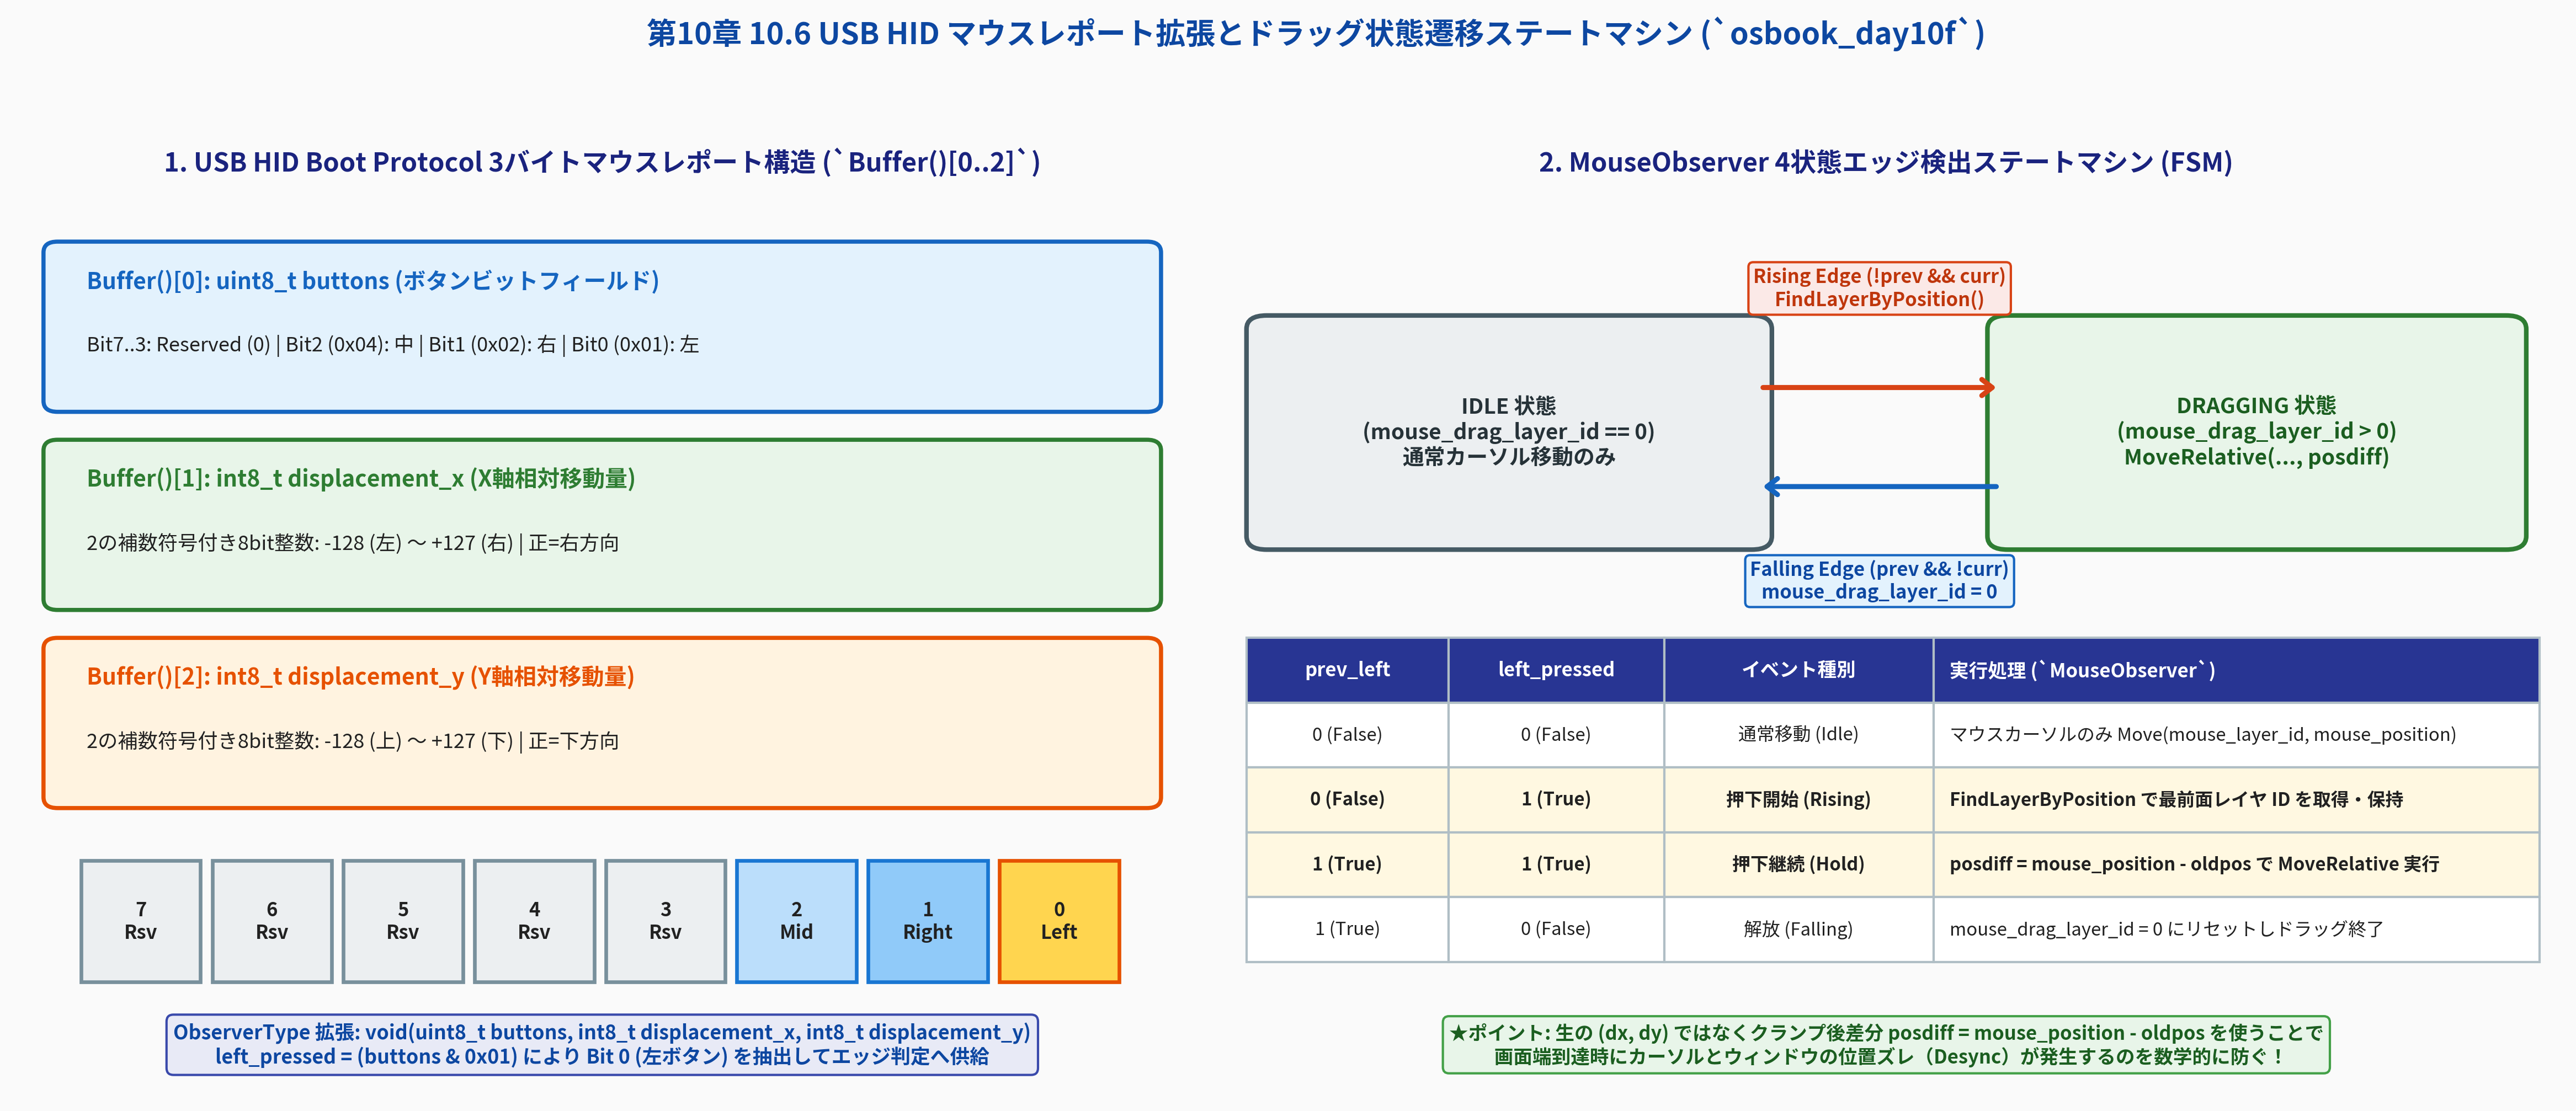

In [2]:
# 図版 10.16: USB HID Boot Protocol 3バイトマウスレポートと MouseObserver 4状態 FSM の生成と表示
from IPython.display import Image, display
from common import generate_ch10_16_usb_hid_mouse_report_and_drag_fsm

fig16_path = generate_ch10_16_usb_hid_mouse_report_and_drag_fsm(
    "10/result/fig10_16_usb_hid_mouse_report_and_drag_fsm.png"
    if Path.cwd().name != "10"
    else "result/fig10_16_usb_hid_mouse_report_and_drag_fsm.png"
)
print(f"保存完了: {fig16_path}")
display(Image(filename=str(fig16_path)))

---

## 2. 最前面レイヤ探索 `LayerManager::FindLayerByPosition` (`layer.hpp`, `layer.cpp`)

左ボタンが押されたとき、カーソル先端座標 `mouse_position` $= (x_m, y_m)$ の真下にどのウィンドウがあるかを特定する必要があります。これが **`LayerManager::FindLayerByPosition`** です。

### 2.1 `osbook_day10f` 実装コードの 1 行単位解読

```cpp
// kernel/layer.hpp
/** @brief 指定された座標にウィンドウを持つ最も上に表示されているレイヤーを探す。 */
Layer* FindLayerByPosition(Vector2D<int> pos, unsigned int exclude_id) const;
```

```cpp
// kernel/layer.cpp
Layer* LayerManager::FindLayerByPosition(Vector2D<int> pos, unsigned int exclude_id) const {
  auto pred = [pos, exclude_id](Layer* layer) {
    if (layer->ID() == exclude_id) {       // (1) マウスカーソル自身のレイヤを除外
      return false;
    }
    const auto& win = layer->GetWindow();  // (2) ウィンドウを持たない空レイヤを除外
    if (!win) {
      return false;
    }
    const auto win_pos = layer->GetPosition();
    const auto win_end_pos = win_pos + win->Size();
    return win_pos.x <= pos.x && pos.x < win_end_pos.x &&
           win_pos.y <= pos.y && pos.y < win_end_pos.y;  // (3) 半開区間ヒットテスト
  };
  auto it = std::find_if(layer_stack_.rbegin(), layer_stack_.rend(), pred);
  if (it == layer_stack_.rend()) {
    return nullptr;
  }
  return *it;
}
```

### 2.2 設計上の 4 つの数学的・アーキテクチャ的必然性

```mermaid
flowchart TD
    Start["FindLayerByPosition(pos, exclude_id = mouse_layer_id)"] --> Loop["layer_stack_.rbegin() から rend() へ逆順走査"]
    Loop --> C1{"layer->ID() == exclude_id ?"}
    C1 -- Yes --> Next["false (次の下位レイヤへ)"]
    C1 -- No --> C2{"layer->GetWindow() != nullptr ?"}
    C2 -- No --> Next
    C2 -- Yes --> C3{"win_pos <= pos < win_pos + size ?"}
    C3 -- No --> Next
    C3 -- Yes --> Hit["★ 最前面レイヤ確定: return *it"]
    Next --> End{"it == rend() ?"}
    End -- No --> Loop
    End -- Yes --> Null["return nullptr (該当なし)"]
```

1. **なぜ `exclude_id`（＝ `mouse_layer_id`）が絶対必須なのか？**
   - `mouse_layer` は常に `layer_stack_` の最上位（`height = 3`）に配置されており、その原点座標 `layer->GetPosition()` はまさに `mouse_position` そのものです。
   - したがって `exclude_id` で除外しなければ、`FindLayerByPosition` は **100% の確率でマウスカーソル自身のレイヤを返してしまい**、背後のウィンドウを永遠に掴めません。
2. **なぜ `rbegin()` 〜 `rend()` の逆イテレータで走査するのか？**
   - 描画処理（Painter's Algorithm）では、`layer_stack_` の先頭（`begin()`, Z=0）から末尾（`end()-1`, Z=max）に向かって上書き描画します。つまり **末尾にあるレイヤほど視覚的に手前（最前面）** にあります。
   - 逆イテレータ `rbegin()` から走査して最初に条件を満たした要素 `*it` を返すことで、複数ウィンドウが重なっていても必ず「ユーザーに見えている一番上のウィンドウ」だけを $\mathcal{O}(N_{\text{layers}})$ で特定できます。
   - さらに、`Hide(id)` で非表示にされたレイヤは `layer_stack_` から削除済み（実体コンテナ `layers_` には残るが描画スタックには無い）ため、`layer_stack_` を走査するだけで**非表示ウィンドウを誤って掴むバグを構造的に防止**できます。
3. **半開区間（Half-open Interval）による厳密な矩形包含判定**:
   - ウィンドウの原点 $(x_0, y_0) = \text{win\_pos}$、サイズ $(w, h) = \text{win->Size()}$ に対して、終端座標を $(x_1, y_1) = (x_0 + w, y_0 + h)$ とおくと、ウィンドウが占有するピクセル集合は
     $$R = [x_0, x_0 + w) \times [y_0, y_0 + h) = \{ (x, y) \in \mathbb{Z}^2 \mid x_0 \le x < x_1 \;\land\; y_0 \le y < y_1 \}$$
   - 右端 $x = x_0 + w$ と下端 $y = y_0 + h$ を **未満 (`<`)** で除外することで、例えば幅 `160` のウィンドウが $[300, 460)$ を占めるときに隣接する $[460, 620)$ のウィンドウと境界座標 `460` で二重ヒット（Off-by-one 衝突）することを防ぎます。
4. **`const auto& win = layer->GetWindow();` と `!win` ガード**:
   - 将来的に装飾枠やダミーノードとして `Window` 未設定の `Layer` が `layer_stack_` に存在しても、`win->Size()` のヌルポインタ間接参照（ページフォルト / トリプルフォルト）を起こさずに安全にスキップします。

保存完了: result/fig10_17_find_layer_by_position_z_order_hit_test.png


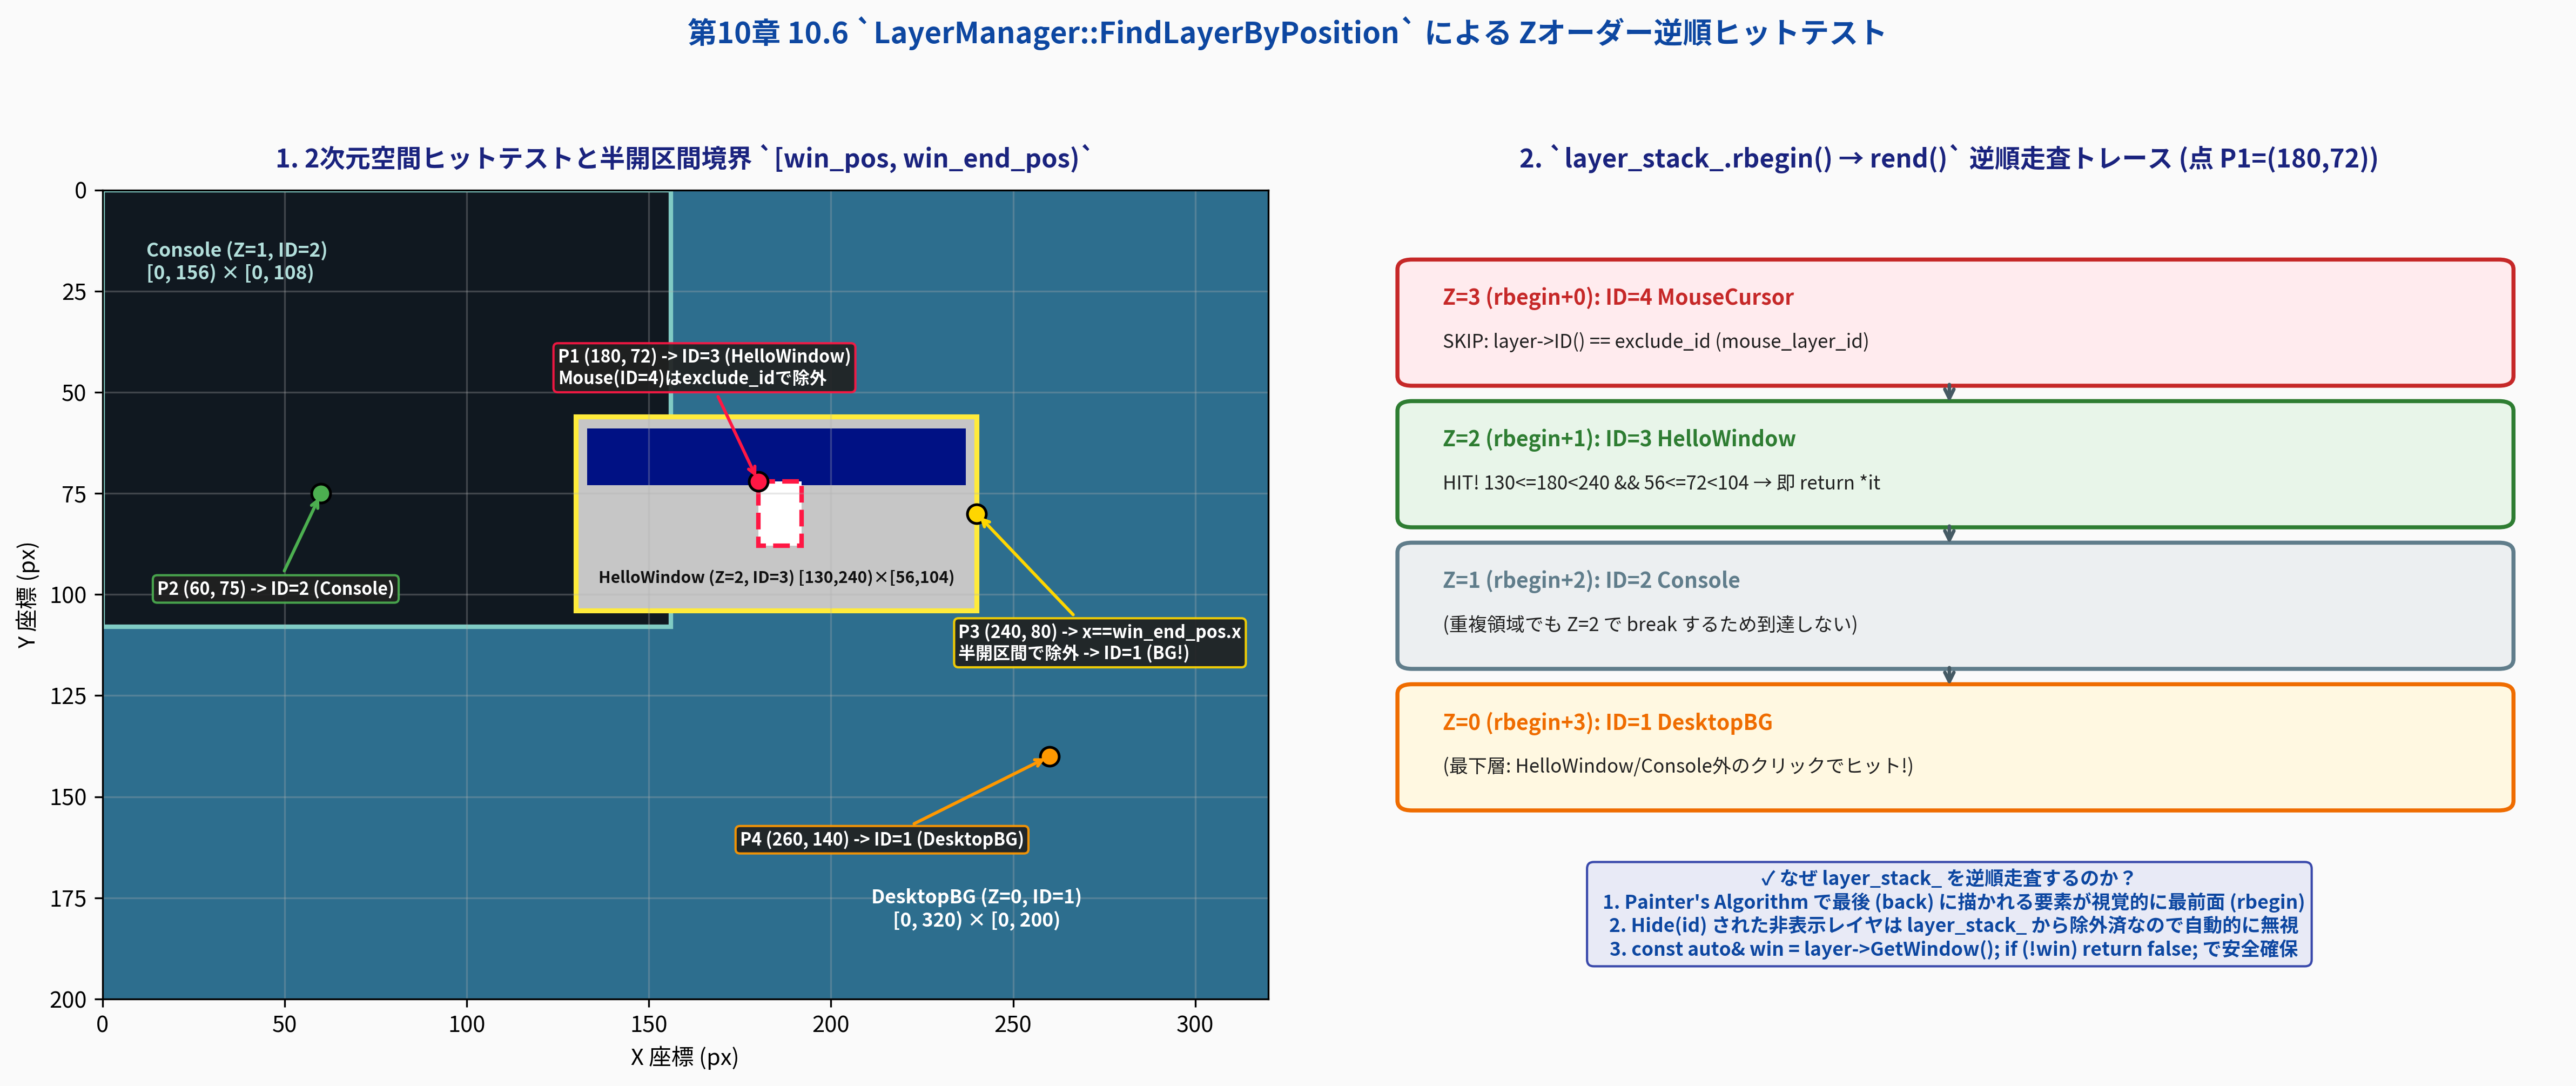

In [3]:
# 図版 10.17: LayerManager::FindLayerByPosition の 2次元空間ヒットテストと rbegin()->rend() 走査トレース
from common import generate_ch10_17_find_layer_by_position_z_order_hit_test

fig17_path = generate_ch10_17_find_layer_by_position_z_order_hit_test(
    "10/result/fig10_17_find_layer_by_position_z_order_hit_test.png"
    if Path.cwd().name != "10"
    else "result/fig10_17_find_layer_by_position_z_order_hit_test.png"
)
print(f"保存完了: {fig17_path}")
display(Image(filename=str(fig17_path)))

---

## 3. `MouseObserver` のドラッグ状態遷移マシン (FSM) と画面端同期数理 (`main.cpp`)

`HIDMouseDriver` から `(buttons, displacement_x, displacement_y)` が届くたびに呼ばれる `MouseObserver` (`kernel/main.cpp`) が、ドラッグ操作の中核を担います。

### 3.1 `osbook_day10f` の `MouseObserver` 全文解説

```cpp
// kernel/main.cpp
void MouseObserver(uint8_t buttons, int8_t displacement_x, int8_t displacement_y) {
  static unsigned int mouse_drag_layer_id = 0;
  static uint8_t previous_buttons = 0;

  const auto oldpos = mouse_position;
  auto newpos = mouse_position + Vector2D<int>{displacement_x, displacement_y};
  newpos = ElementMin(newpos, screen_size + Vector2D<int>{-1, -1});
  mouse_position = ElementMax(newpos, {0, 0});

  const auto posdiff = mouse_position - oldpos;

  layer_manager->Move(mouse_layer_id, mouse_position);

  const bool previous_left_pressed = (previous_buttons & 0x01);
  const bool left_pressed = (buttons & 0x01);
  if (!previous_left_pressed && left_pressed) {
    auto layer = layer_manager->FindLayerByPosition(mouse_position, mouse_layer_id);
    if (layer) {
      mouse_drag_layer_id = layer->ID();
    }
  } else if (previous_left_pressed && left_pressed) {
    if (mouse_drag_layer_id > 0) {
      layer_manager->MoveRelative(mouse_drag_layer_id, posdiff);
    }
  } else if (previous_left_pressed && !left_pressed) {
    mouse_drag_layer_id = 0;
  }

  previous_buttons = buttons;
}
```

### 3.2 設計の核心ポイント

1. **`static unsigned int mouse_drag_layer_id = 0;` が番兵（Sentinel）として機能する理由**:
   - `LayerManager::NewLayer()` は `++latest_id_;`（初期値 `0` を前置インクリメント）するため、有効なレイヤ ID は必ず **`1` 以上**（$1, 2, 3, \dots$）になります。
   - したがって `mouse_drag_layer_id == 0` は「現在どのレイヤもドラッグしていない」という非ドラッグ状態を曖昧さゼロで表せます。
2. **4状態エッジ検出（Edge Detection）真理値表**:

   | `previous_left_pressed` | `left_pressed` | 状態遷移 | 実行される分岐・処理 |
   |:---:|:---:|---|---|
   | `false` (`0`) | `false` (`0`) | **Idle**（通常移動） | カーソルのみ移動（どの `if` 分岐にも入らない） |
   | `false` (`0`) | `true` (`1`) | **Rising Edge**（押下開始） | `FindLayerByPosition(mouse_position, mouse_layer_id)` で対象レイヤを探し `mouse_drag_layer_id` に記録 |
   | `true` (`1`) | `true` (`1`) | **Hold**（ドラッグ継続） | `mouse_drag_layer_id > 0` なら `MoveRelative(mouse_drag_layer_id, posdiff)` で移動 |
   | `true` (`1`) | `false` (`0`) | **Falling Edge**（解放） | `mouse_drag_layer_id = 0` にリセットしてドラッグ終了 |

3. **なぜ生の `(displacement_x, displacement_y)` ではなく `posdiff = mouse_position - oldpos` を使うのか？**
   - もし画面右端 $(W-1 = 1023)$ に近い位置 $x_{\text{old}} = 1015$ でウィンドウをドラッグ中に、マウスから $\Delta x = +20$ が届いたとします。
   - マウスカーソル座標は画面外に出ないようクランプされるため、
     $$x_{\text{new}} = \max\!\big(0,\; \min(W - 1,\; x_{\text{old}} + \Delta x)\big) = \min(1023, 1035) = 1023$$
   - このとき実際のカーソル移動量は $\text{posdiff}_x = x_{\text{new}} - x_{\text{old}} = 1023 - 1015 = +8$ です。
   - もしウィンドウ移動に生の $\Delta x = +20$ を使ってしまうと、カーソルは `1023` で止まっているのにウィンドウだけがさらに `12px` 右へ滑ってしまい、**カーソルとウィンドウの相対位置不変性（$x_{\text{mouse}} - x_{\text{win}} = \text{const}$）が崩壊（Desync）** します。
   - `posdiff = mouse_position - oldpos` を使うことで、画面端でカーソルが止まった瞬間にウィンドウの移動量も自動的に `+8` で止まり、左右逆向きに戻したときも掴んだ位置から 1 ピクセルもズレずに追従します！
4. **`LayerManager::MoveRelative(id, posdiff)` とダブルバッファリングの協奏**:
   - `MoveRelative` は `layer->MoveRelative(pos_diff)`（内部の `pos_ += pos_diff`）を呼んだあと、`Draw({old_pos, window_size})` と `Draw(id)` を実行します。
   - 第10.5節で導入した `back_buffer_` のおかげで、ドラッグ中にウィンドウをどれだけ高速に動かしても**移動前の背景（コンソールやデスクトップ）がチラつきゼロで綺麗に復元**されます。

In [4]:
# 対話型 Python 実験 1: HID 3バイトデコード & FindLayerByPosition 逆順走査トレース検証
from common import DoubleBufferLayerSpec, HidMouseReport, WindowDragSim
import numpy as np

# 1. USB HID Boot Protocol 3バイト (2の補数符号付き変位・ボタンビットマスク) の復号実験
test_packets = [
    (0x00, 0x0A, 0x05),  # ボタンなし, dx=+10, dy=+5
    (0x01, 0x28, 0xEC),  # 左ボタン押下, dx=+40, dy=-20 (0xEC = 236 -> -20)
    (0x05, 0x80, 0xFF),  # 左+中ボタン押下, dx=-128 (0x80), dy=-1 (0xFF)
]
print("=== 1. USB HID 3バイトマウスレポート復号実験 ===")
for b0, b1, b2 in test_packets:
    rep = HidMouseReport.from_bytes(b0, b1, b2)
    print(
        f"Raw=[0x{b0:02X}, 0x{b1:02X}, 0x{b2:02X}] -> "
        f"Left={rep.left_pressed}, Right={rep.right_pressed}, Mid={rep.middle_pressed}, "
        f"dx={rep.displacement_x:+4d}, dy={rep.displacement_y:+4d}"
    )

# 2. FindLayerByPosition の Zオーダー逆順探索・半開区間・!win・Hide 免疫の検証
sim = WindowDragSim.create_mikanos_desktop_sim(320, 200, init_mouse_pos=(180, 72))
sim.add_layer(
    DoubleBufferLayerSpec(5, "NoWindowDummy", 120, 50, 120, 60, np.zeros((60, 120, 3), dtype=np.uint8)),
    has_window=False,
    height=3,
)
sim.add_layer(
    DoubleBufferLayerSpec(6, "HiddenWin", 120, 50, 120, 60, np.zeros((60, 120, 3), dtype=np.uint8)),
    has_window=True,
    height=-1,
)
sim.up_down(4, 10)  # MouseCursor を最前面に戻す

print("\n=== 2. FindLayerByPosition(pos, exclude_id=4) 逆順走査トレース ===")
probe_points = [
    ((180, 72), "HelloWindow & Mouse 重複点"),
    ((140, 80), "HelloWindow & Console 重複点"),
    ((60, 75), "Console 単独領域"),
    ((240, 80), "HelloWindow 右端境界 x==240 (半開区間で除外)"),
    ((260, 150), "デスクトップ背景単独領域 (10.6節のバグ誘発点)"),
]
for pos, desc in probe_points:
    hit_id, trace = sim.find_layer_by_position(pos, exclude_id=4)
    print(f"\n[Probe {pos}: {desc}] -> 結果: Layer ID={hit_id}")
    for row in trace:
        print(f"   Z={row['z']} ID={row['layer_id']} ({row['name']:13s}) : {row['result']}")

=== 1. USB HID 3バイトマウスレポート復号実験 ===
Raw=[0x00, 0x0A, 0x05] -> Left=False, Right=False, Mid=False, dx= +10, dy=  +5
Raw=[0x01, 0x28, 0xEC] -> Left=True, Right=False, Mid=False, dx= +40, dy= -20
Raw=[0x05, 0x80, 0xFF] -> Left=True, Right=False, Mid=True, dx=-128, dy=  -1

=== 2. FindLayerByPosition(pos, exclude_id=4) 逆順走査トレース ===

[Probe (180, 72): HelloWindow & Mouse 重複点] -> 結果: Layer ID=3
   Z=4 ID=4 (MouseCursor  ) : SKIP (exclude_id)
   Z=3 ID=5 (NoWindowDummy) : SKIP (!win)
   Z=2 ID=3 (HelloWindow  ) : HIT [130,240)x[56,104)

[Probe (140, 80): HelloWindow & Console 重複点] -> 結果: Layer ID=3
   Z=4 ID=4 (MouseCursor  ) : SKIP (exclude_id)
   Z=3 ID=5 (NoWindowDummy) : SKIP (!win)
   Z=2 ID=3 (HelloWindow  ) : HIT [130,240)x[56,104)

[Probe (60, 75): Console 単独領域] -> 結果: Layer ID=2
   Z=4 ID=4 (MouseCursor  ) : SKIP (exclude_id)
   Z=3 ID=5 (NoWindowDummy) : SKIP (!win)
   Z=2 ID=3 (HelloWindow  ) : MISS [130,240)x[56,104)
   Z=1 ID=2 (Console      ) : HIT [0,156)x[0,108)

[Probe (240, 8

In [5]:
# 対話型 Python 実験 2: MouseObserver 4状態 FSM トレース & 画面端クランプ時の posdiff 同期証明
sim_fsm = WindowDragSim.create_mikanos_desktop_sim(320, 200, init_mouse_pos=(180, 72))
init_win_pos = (sim_fsm.db_sim.layers[3].x, sim_fsm.db_sim.layers[3].y)
init_offset = (sim_fsm.mouse_position[0] - init_win_pos[0], sim_fsm.mouse_position[1] - init_win_pos[1])

packets = [
    (0x00, 10, 4),    # Idle移動: カーソルだけ (190, 76) へ
    (0x01, 0, 0),     # Rising Edge: (190, 76) で HelloWindow (ID=3) 選択
    (0x01, 127, 10),  # Hold: 右へ +127 -> (317, 86), HelloWindow -> (257, 66)
    (0x01, 30, 0),    # Hold (画面端クランプ!): raw=347 -> clamped=319 -> posdiff=(+2, 0) のみ!
    (0x01, -40, 20),  # Hold (左へ戻す): (279, 106), HelloWindow -> (219, 86)
    (0x00, -10, -5),  # Falling Edge: ボタン解放 -> mouse_drag_layer_id = 0
]

print(f"初期ウィンドウ座標: {init_win_pos}, 初期カーソル相対オフセット: {init_offset}")
print("-" * 112)
for b, dx, dy in packets:
    e = sim_fsm.mouse_observer(b, dx, dy)
    cur_win = (sim_fsm.db_sim.layers[3].x, sim_fsm.db_sim.layers[3].y)
    cur_offset = (e.new_mouse_pos[0] - cur_win[0], e.new_mouse_pos[1] - cur_win[1])
    print(
        f"Step {e.step}: btn=0x{e.buttons:02X} raw=({e.dx:+4d},{e.dy:+4d}) "
        f"mouse={str(e.new_mouse_pos):10s} posdiff={str(e.posdiff):9s} "
        f"| {e.transition:26s} | drag_id={e.drag_layer_id} win={str(cur_win):10s} offset={cur_offset}"
    )

# 不変性アサーション: ドラッグ中（Step 2〜5）は画面右端でクランプされても相対オフセット (60, 20) が厳密に不変！
drag_offsets = [
    (e.new_mouse_pos[0] - e.drag_layer_pos[0], e.new_mouse_pos[1] - e.drag_layer_pos[1])
    for e in sim_fsm.trace
    if e.drag_layer_id == 3 and e.drag_layer_pos is not None
]
assert len(drag_offsets) == 4
assert all(off == (60, 20) for off in drag_offsets)
assert sim_fsm.trace[5].drag_layer_id == 0
print("\n✅ 画面端クランプ後もドラッグ中のカーソルとウィンドウの相対位置 (60, 20) が 1px のズレもなく同期していることを実証しました！")

初期ウィンドウ座標: (130, 56), 初期カーソル相対オフセット: (50, 16)
----------------------------------------------------------------------------------------------------------------
Step 1: btn=0x00 raw=( +10,  +4) mouse=(190, 76)  posdiff=(10, 4)   | IDLE (Cursor Move)         | drag_id=0 win=(130, 56)  offset=(60, 20)
Step 2: btn=0x01 raw=(  +0,  +0) mouse=(190, 76)  posdiff=(0, 0)    | RISING_EDGE (Drag Start)   | drag_id=3 win=(130, 56)  offset=(60, 20)
Step 3: btn=0x01 raw=(+127, +10) mouse=(317, 86)  posdiff=(127, 10) | HOLD (Dragging)            | drag_id=3 win=(257, 66)  offset=(60, 20)
Step 4: btn=0x01 raw=( +30,  +0) mouse=(319, 86)  posdiff=(2, 0)    | HOLD (Dragging)            | drag_id=3 win=(259, 66)  offset=(60, 20)
Step 5: btn=0x01 raw=( -40, +20) mouse=(279, 106) posdiff=(-40, 20) | HOLD (Dragging)            | drag_id=3 win=(219, 86)  offset=(60, 20)
Step 6: btn=0x00 raw=( -10,  -5) mouse=(269, 101) posdiff=(-10, -5) | FALLING_EDGE (Drag End)    | drag_id=0 win=(219, 86)  offset=(50, 15)



---

## 4. 10.6節で顕在化する残存バグ ― デスクトップ背景・コンソールもドラッグされてしまう問題

上記のコードで `Hello Window` は完璧にドラッグできるようになりました。しかし、`osbook_day10f` を実機や QEMU で動かして**デスクトップの何もない青い背景部分**をクリックしてドラッグすると、驚くべき現象が発生します：

> **背景の青色デスクトップ全体（`bglayer_id`）やコンソール画面（`console->LayerID()`）までマウスに追従してズリ動いてしまう！**

### なぜこのバグが起きるのか？（構造的原因の解剖）

`kernel/main.cpp` のレイヤ構築処理を確認すると、以下の 4 つのレイヤがすべて有効な `Window` オブジェクトを保持しています：

| Z オーダー | レイヤ ID 変数 | `Window` サイズ | 本来ドラッグ可能か？ | `osbook_day10f` での判定 |
|:---:|---|---|---|:---:|
| `0` | `bglayer_id` | `1024 × 768`（全画面） | ❌ **不可**（固定背景） | ⚠️ **ヒットしてドラッグ可能** |
| `1` | `console->LayerID()` | `640 × 400`（80列×25行） | ❌ **不可**（固定コンソール） | ⚠️ **ヒットしてドラッグ可能** |
| `2` | `main_window_layer_id` | `160 × 52`（`Hello Window`） | ✅ **可能** | ✅ **ドラッグ可能** |
| `3` | `mouse_layer_id` | `15 × 24`（マウスカーソル） | ❌ 除外 (`exclude_id`) | ✅ 除外済み |

`FindLayerByPosition` は「`exclude_id` でなく、かつ `Window` を持つ最前面レイヤ」を返す仕様であるため、`Hello Window` の外側をクリックすると **必ず `console` または `bgwindow` にヒット** してしまいます。しかも最下層の `bglayer_id`（Z=0）が動いてしまうと、その下に背景レイヤが存在しないため `back_buffer_` に以前の描画残像がそのまま取り残されて画面が崩れます。

このバグを根本解決するのが、次節 **10.7「ウィンドウだけドラッグ移動 (`osbook_day10g`)」** で導入する `Layer::draggable_` フラグです。

保存完了: result/fig10_18_window_drag_trajectory_and_bg_bug.png


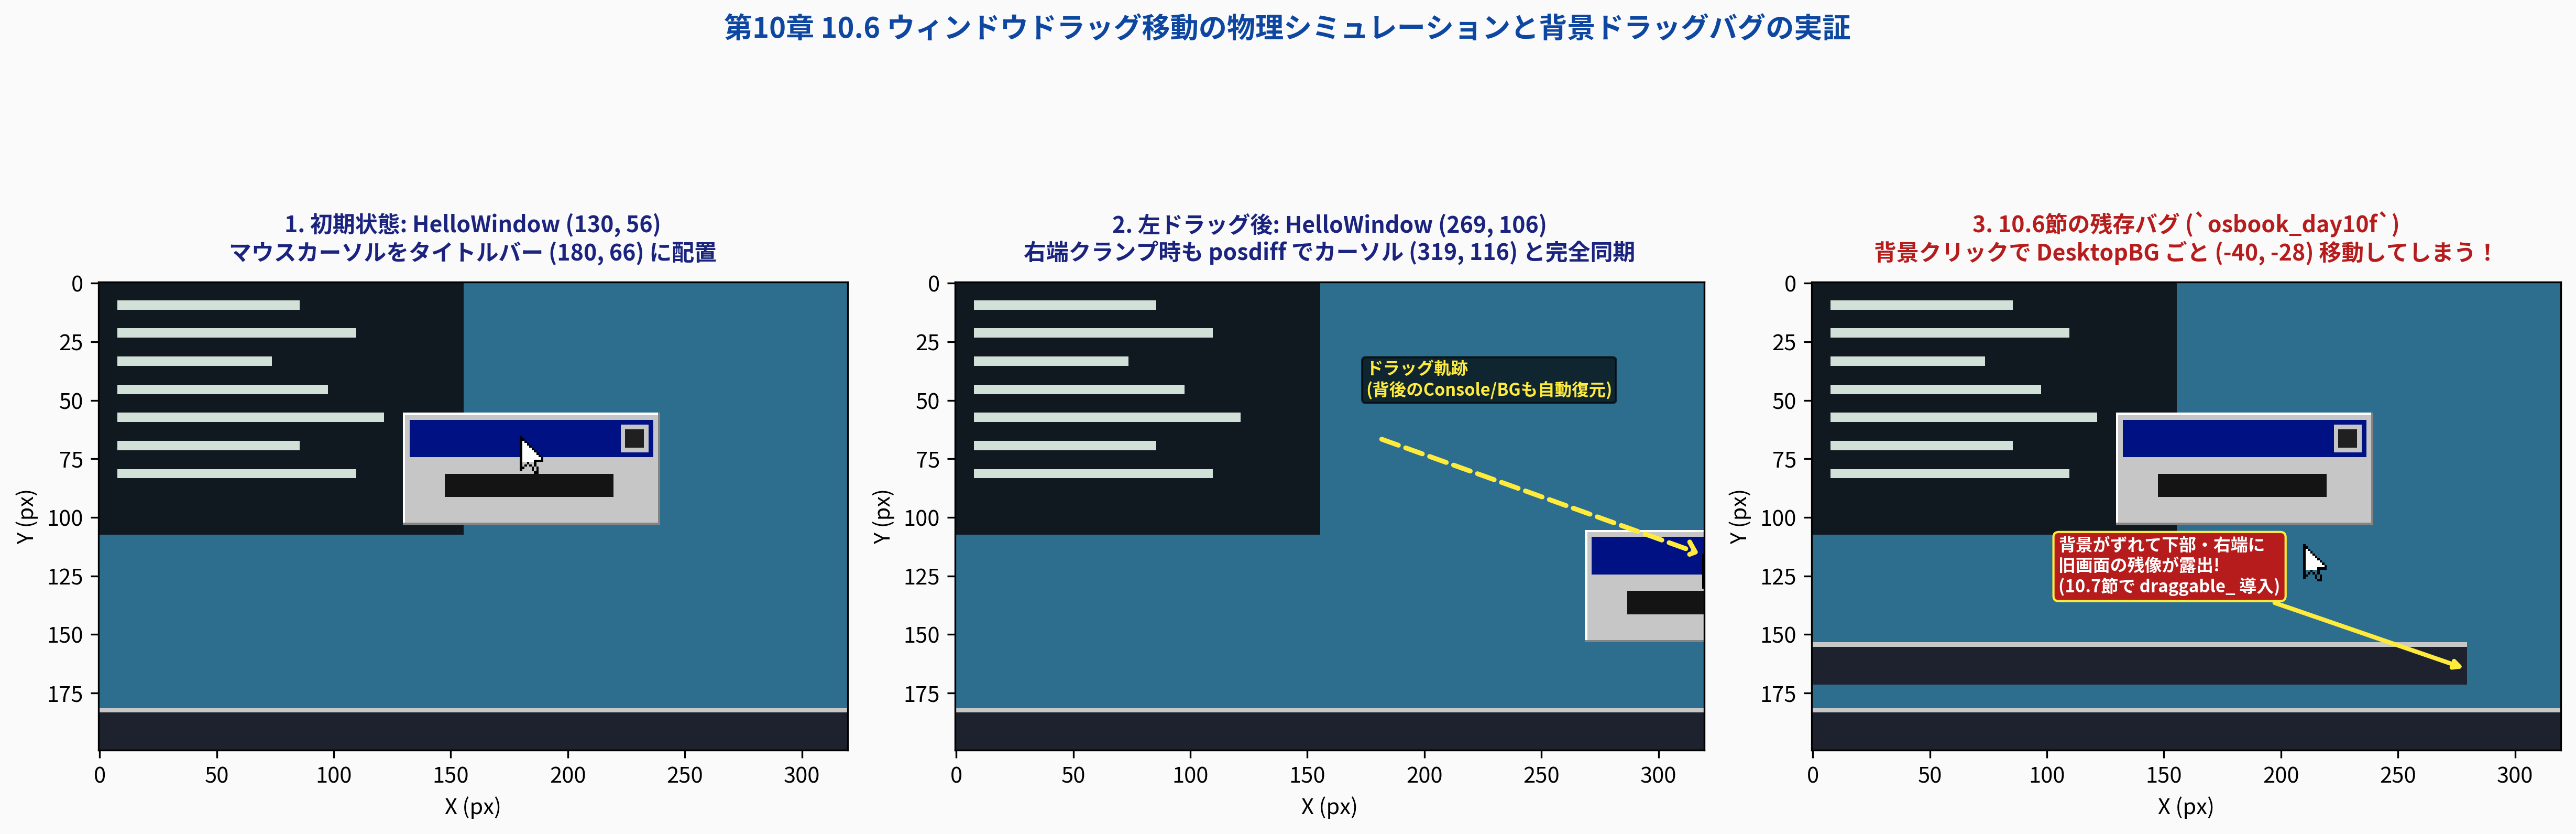

In [6]:
# 図版 10.18: HelloWindow のドラッグ軌道・画面端同期と osbook_day10f 背景ドラッグバグのシミュレーション可視化
from common import generate_ch10_18_window_drag_trajectory_and_bg_bug

fig18_path = generate_ch10_18_window_drag_trajectory_and_bg_bug(
    "10/result/fig10_18_window_drag_trajectory_and_bg_bug.png"
    if Path.cwd().name != "10"
    else "result/fig10_18_window_drag_trajectory_and_bg_bug.png"
)
print(f"保存完了: {fig18_path}")
display(Image(filename=str(fig18_path)))

---

## 5. スタンドアロン C++20 実装のビルドと単体検証 (`src/ch10/os_chapter10_dragging_windows.cpp`)

MikanOS の `osbook_day10f` における以下の実装をホスト環境向け C++20 プログラム [`src/ch10/os_chapter10_dragging_windows.cpp`](../src/ch10/os_chapter10_dragging_windows.cpp) として切り出し、`g++ -std=c++20 -O2 -Wall -Wextra -Wpedantic`（および AddressSanitizer / UndefinedBehaviorSanitizer）で検証します：

1. `LayerManager::FindLayerByPosition(pos, exclude_id)`:
   - `exclude_id`（マウスレイヤ）、`!win`（ウィンドウ未設定レイヤ）、`Hide()` された非表示レイヤをすべて正しくスキップすること。
   - 半開区間 `[win_pos, win_pos + size)` の境界ピクセル（内端 `100, 50` はヒット、外端 `200, 94` はミス）が厳密に正しいこと。
2. `HIDMouseDriverSim::OnDataReceived` + `DesktopController::MouseObserver`:
   - 3バイト HID レポートの 2の補数負値（`int8_t{-20}`）とボタンマスク `0x01` を正確に伝播すること。
   - 画面右端 `319` クランプ時に `posdiff` が実移動量 `22` のみを反映し、カーソルとウィンドウの位置ズレが起きないこと。
   - ダブルバッファリング `back_buffer_` と `screen` (VRAM) が移動前後で全ピクセル完全一致すること。
3. `osbook_day10f` の背景レイヤドラッグバグが仕様どおり再現されること。

In [7]:
# C++20 スタンドアロン検証プログラムの実行
import subprocess
from pathlib import Path

binary_path = Path("build/bin/ch10_dragging_windows")
if not binary_path.exists():
    binary_path = Path("../build/bin/ch10_dragging_windows")

if not binary_path.exists():
    print("CMake ビルドを実行中...")
    build_dir = Path("build") if Path("build").exists() else Path("../build")
    subprocess.run(["cmake", "--build", str(build_dir), "--target", "ch10_dragging_windows"], check=True)

result = subprocess.run([str(binary_path)], capture_output=True, text=True, check=True)
print(result.stdout)

=== Chapter 10.6 Window Dragging Verification (osbook_day10f) ===
FindLayerByPosition Z-order + half-open [pos, pos+size) checks: PASS
Clamped posdiff edge sync: main_win moved to (289, 30) with cursor at (319, 45)
osbook_day10f Background Drag Bug reproduced: bg_id=1 dragged to (15, 10)
All C++20 Chapter 10.6 Assertions PASSED Successfully!



---

## 6. まとめと第10章 10.7 への展望

### 本節で達成した成果
1. **USB HID マウスボタン情報の統合 (`mouse.hpp` / `mouse.cpp`)**:
   - Boot Protocol 3バイトレポートの `Buffer()[0]`（`buttons`）を `HIDMouseDriver::ObserverType` に追加し、左ボタン状態（`buttons & 0x01`）を OS カーネルの `MouseObserver` へ届けられるようになりました。
2. **Z オーダー逆順ヒットテスト `FindLayerByPosition` の実装 (`layer.hpp` / `layer.cpp`)**:
   - `layer_stack_.rbegin()` 〜 `rend()` の逆順走査、`exclude_id` によるマウス除外、`!win` ヌルガード、半開区間矩形判定 `[win_pos, win_end_pos)` を組み合わせ、クリック地点の最前面ウィンドウを高速・安全に特定しました。
3. **エッジ検出 FSM とクランプ同期ドラッグ (`main.cpp`)**:
   - `previous_buttons` と `mouse_drag_layer_id` による 4状態 FSM と、`posdiff = mouse_position - oldpos` に基づく `MoveRelative` により、画面端に当たってもズレない滑らかなウィンドウドラッグを実現しました。

---

### 次節への道: 10.7 ウィンドウだけドラッグ移動 (`osbook_day10g`)
本節の最後で確認したとおり、現状では背景（`bgwindow`）やコンソール（`console_window`）までクリック一発でドラッグできてしまうバグが残っています。
次節 **10.7「ウィンドウだけドラッグ移動 (`osbook_day10g`)」** では：
- `Layer` クラスへの `bool draggable_{false};` メンバおよび `SetDraggable(bool)` / `IsDraggable()` アクセサの追加
- `FindLayerByPosition` によるヒット後に `layer->IsDraggable()` をチェック（またはドラッグ可否フィルタリング）する設計
- 通常の GUI ウィンドウだけが移動し、デスクトップ背景とコンソールが固定される安全・完成度の高い GUI デスクトップの完成

を実装します！